In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import torch
import dataset as ds

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_percentage_error, 
    root_mean_squared_error
)

import xgboost as xgb

# Define global variables

In [6]:
NO_DATA_VALUE = -9999

VI_BANDS_NAMES = ['NDVI', 'BNDVI', 'GNDVI', 'GBNDVI', 'GRNDVI', 'RBNDVI']

WB_WEATHER_BANDS_NAMES = [
    'min T', 'mean T', 'T', 'max T',
    'min rel. hum.', 'mean rel. hum.', 'rel. hum.', 'max rel. hum.',
    'min pressure', 'mean pressure', 'max pressure',
    'max gust', 'wind direction', 'wind speed',
    'precipitation', 'global energy'
]

SPECTRAL_BANDS_NAMES, WB_WEATHER_BANDS_RS_NAMES = [
    'NIR', 'R', 'G', 'B', *VI_BANDS_NAMES
], [
    f'{band}; T{time}' for band, time in np.array(
        np.meshgrid(WB_WEATHER_BANDS_NAMES, ['0', '8', '16'])
    ).T.reshape(-1, 2)
]

ALL_FEATURES = [*SPECTRAL_BANDS_NAMES, *WB_WEATHER_BANDS_RS_NAMES]

# Error metrics

In [ ]:
def smape_pixel(actual, forecast, handle_zeros='zero'):
    if len(actual) != len(forecast):
        raise ValueError("Lengths must match")
    
    errors = []
    for a, f in zip(actual, forecast):
        denom = (abs(a) + abs(f)) / 2
        if denom == 0:
            if handle_zeros == 'zero':
                errors.append(0.0)
            elif handle_zeros == 'raise':
                raise ValueError("Zero denominator encountered")
            # 'exclude' skips automatically
        else:
            errors.append(abs(a - f) / denom)
            
    if not errors:
        raise ValueError("No valid points to compute SMAPE")
    return (sum(errors) / len(errors)) * 100

# Fertilization Data (Main Table)

In [8]:
N_BANDS = 18

patches_dataset_clean = pd.read_pickle(
    './data/pkl/'+\
    f'Targeted fertilization v3.patches_dataset.kernel=8_stride=1_bands={N_BANDS}.weather.land=Wheat_ph=2.v3.pkl'
)

# Get train / dev / test images

In [9]:
gerk_train, gerk_dev, gerk_test = pd.read_pickle(
    f'./data/pkl/'
    f'Targeted fertilization v3.patches_dataset.kernel=8_stride=1_bands={N_BANDS}.weather.land=Wheat_ph=2.v3.train-dev-test-splits.pkl'
)

# Feature selection

In [10]:
# # Feature Selection
selected_features = [
    'NIR', 'R', 'G', 'B', "BNDVI", 
    "min T; T0", "min T; T8", "min T; T16", 
    "mean rel. hum.; T0", "mean rel. hum.; T8", "mean rel. hum.; T16",
    "mean pressure; T0", "mean pressure; T8", "mean pressure; T16", 
    "max gust; T0", 
    "wind direction; T0", 
    "wind speed; T16", 
    "global energy; T0"
]
selected_features_ix = [ALL_FEATURES.index(i) for i in selected_features]

In [11]:
X, y = {}, {}

for rec in patches_dataset_clean.itertuples():
    rec_input, rec_output = rec.input, rec.output
    mask = torch.argwhere(rec_output != NO_DATA_VALUE)

    X[rec.Index] = rec_input[0, :, mask[:, 2], mask[:, 3]][selected_features_ix, :].numpy().T
    y[rec.Index]= rec_output[0, :, mask[:, 2], mask[:, 3]].numpy().T

X, y = pd.Series(X), pd.Series(y)

# Split to train / dev / test dataset

In [12]:
# Getting the correponding raster patches
X_train_dev, y_train_dev, X_test, y_test = X.loc[
    pd.IndexSlice[[*gerk_train, *gerk_dev], :, :]
].copy(), y.loc[
    pd.IndexSlice[[*gerk_train, *gerk_dev], :, :]
].copy(), X.loc[
    pd.IndexSlice[gerk_test, :, :]
].copy(), y.loc[
    pd.IndexSlice[gerk_test, :, :]
].copy()

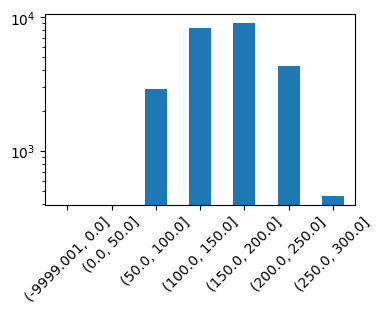

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4/1.618))

out = pd.cut(
    y_train_dev.explode(),
    bins=[NO_DATA_VALUE, 0, 50, 100, 150, 200, 250, 300], 
    include_lowest=True
)

out.value_counts(sort=False).plot.bar(rot=45, ax=ax)
ax.set_yscale('log')

In [ ]:
# ## Split Patches to Train/Dev sets (80%/20%), stratified by (discretized/binned) nitrogen quantity
X_train, X_dev, y_train, y_dev = ds.train_test_split(
    X_train_dev.explode(),
    y_train_dev.explode(),
    test_size=0.2,
    random_state=3407,
    stratify=out
)

# Train ML baselines

In [ ]:
results = {
    'actual': pd.Series(y_test.explode().explode(), name='y')
}

# Define the DNN Architecture (Sajindra et al. 2024)
model_params__dnn = dict(
    hidden_layer_sizes=(10, 10, 10, 10),
    activation='tanh',
    solver='adam',
    max_iter=100,
    random_state=3407,
    early_stopping=True,
    n_iter_no_change=10,
)

for model, model_params, name in zip(
    [DecisionTreeRegressor, xgb.XGBRegressor, SVR, MLPRegressor],
    [{}, {}, {}, model_params__dnn],
    ['CART', 'XGBoost', 'SVMr', 'MLP']
):
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model(**model_params))
    ])

    pipeline.fit(
        np.vstack(X_train.values), 
        np.vstack(y_train)
    )

    results[name] = pd.Series(
        (
            y_test_pred := pipeline.predict(
                np.vstack(X_test.values)
            )
        ).flatten(),
        index=results['actual'].index, 
        name=name
    )

    print(
        f'{name};',
        f'RMSE: {float(root_mean_squared_error(np.vstack(y_test), y_test_pred)):.2f};',
        f'MAPE: {float(mean_absolute_percentage_error(np.vstack(y_test), y_test_pred)*100):.2f};',
        f'SMAPE: {float(smape_pixel(np.vstack(y_test).flatten(), y_test_pred)):.2f}',
        sep='\t\t'
    )

# Concentrating results into a unified table

In [ ]:
y_hats = pd.DataFrame(results)
y_hats.to_pickle('ML_in-channels=18_y_pred_ITC_test_set.v2.pkl.gzip')

# Visualizing results

In [ ]:
y_hats = pd.read_pickle('ML_in-channels=18_y_pred_ITC_test_set.v2.pkl.gzip')

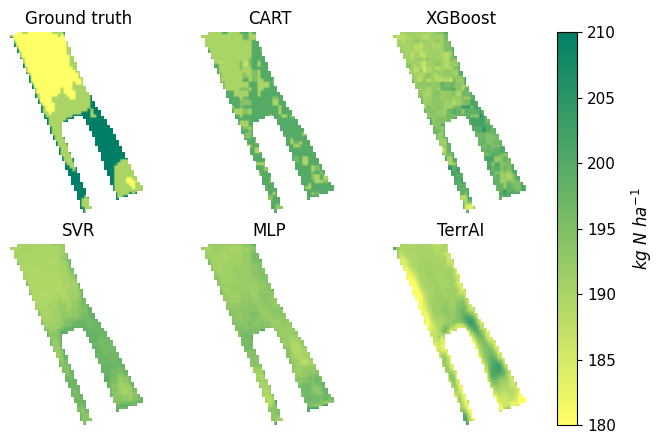

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(7, 7/1.618), sharex=True, sharey=True, constrained_layout=True)

# Selected parcel
mask = pd.IndexSlice[
    gerk_test[0],
    :, 
    :
]

y_test_models = [
    'actual',
    'CART', 
    'XGBoost', 
    'SVMr',
    'MLP'
]
ax_i_titles = [
    'Ground truth',
    *y_test_models[1:-2],
    'SVR',
    'MLP',
    'TerrAI',
]

# Fetch values for colorbar
vmin, vmax = (
    np.min(
        y_hats.loc[
            mask,
            y_test_models
        ].astype(
            int
        ).describe().loc[
            'min'
        ]
    ),
    np.max(
        y_hats.loc[
            mask,
            y_test_models
        ].astype(
            int
        ).describe().loc[
            'max'
        ]
    )
)

# Fetch ground truth image
y_test_image = patches_dataset_clean.loc[
    mask,
    [
        'output'
    ]
]

for (ax_i, ax_i_title, y_test_model) in zip(
    ax.flatten(),
    ax_i_titles,
    y_test_models,
):
    # Title
    ax_i.set_title(ax_i_title)
    ax_i.set_axis_off()
    tmp = np.copy(y_test_image.iloc[0, 0])

    # Image
    if y_test_model == 'actual':
        tmp[tmp == NO_DATA_VALUE] = np.nan
        map_out = ax_i.imshow(
            tmp.squeeze(), 
            cmap='summer_r', 
            vmin=vmin, 
            vmax=vmax
        )
        continue

    tmp[tmp != NO_DATA_VALUE] = y_hats.loc[
        mask, 
        y_test_model
    ]
    tmp[tmp == NO_DATA_VALUE] = np.nan

    map_pred = ax_i.imshow(tmp.squeeze(), cmap='summer_r', vmin=vmin, vmax=vmax)

# Plot U-Net forecast
y_test_unet = np.load(f'UNet_in-channels={N_BANDS}_y_pred_gerk={gerk_test[0]}.npy',)

y_test_unet[y_test_unet == NO_DATA_VALUE] = np.nan
ax[-1][-1].set_title(ax_i_titles[-1])
ax[-1][-1].set_axis_off()
map_pred = ax[-1][-1].imshow(y_test_unet.squeeze(), cmap='summer_r', vmin=vmin, vmax=vmax)


# Colorbars
cax = fig.colorbar(map_pred, ax=ax, orientation='vertical', pad=0.05)
cax.ax.set_ylabel(r'$kg\ N\ ha^{-1}$', labelpad=10, fontsize=12)
cax.ax.tick_params(labelsize=11)

plt.savefig('terrai_vs_ml.v6.png', dpi=300, bbox_inches='tight')